# Taller 2 – 3° Corte: Segmentación panóptica del entorno universitario
**Electiva IV – Deep Computer Vision · Ingeniería Mecatrónica · USTA Bucaramanga**

Integrantes: Kizzye Hidalgo y Catalina Alarcon

En este taller usamos **Mask2Former** (preentrenado en COCO panoptic) para segmentar 6 fotos del campus. La segmentación panóptica junta dos cosas:
- **Thing**: objetos contables con instancias separadas (personas, carros, motos, sillas…).
- **Stuff**: regiones amorfas de fondo (cielo, piso, pared, vegetación…).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 0. Configuración

In [4]:
!pip -q install transformers accelerate

In [5]:
import os, glob, zipfile
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy import ndimage
from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation

MODEL_ID = "facebook/mask2former-swin-large-coco-panoptic"   # si falla por memoria: "facebook/mask2former-swin-tiny-coco-panoptic"
DIR_IMG, DIR_OUT = "imagenes", "salidas"
os.makedirs(DIR_OUT, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


In [6]:
if not glob.glob(f"{DIR_IMG}/*.jpg"):
    from google.colab import files
    os.makedirs(DIR_IMG, exist_ok=True)
    for name in files.upload():                     # sirve subiendo el .zip o las 6 fotos sueltas
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall(".")
        elif name.lower().endswith((".jpg", ".jpeg", ".png")):
            os.replace(name, os.path.join(DIR_IMG, name))
print(sorted(os.listdir(DIR_IMG)))

Saving 05_laboratorio.jpg to 05_laboratorio.jpg
Saving 06_pasillo_casilleros.jpg to 06_pasillo_casilleros.jpg
Saving 01_parqueadero.jpg to 01_parqueadero.jpg
Saving 02_entrada_universidad.jpg to 02_entrada_universidad.jpg
Saving 03_zona_verde.jpg to 03_zona_verde.jpg
Saving 04_cafeteria.jpg to 04_cafeteria.jpg
['01_parqueadero.jpg', '02_entrada_universidad.jpg', '03_zona_verde.jpg', '04_cafeteria.jpg', '05_laboratorio.jpg', '06_pasillo_casilleros.jpg']


## Parte 1. Imágenes del campus
Escogimos 6 fotos que cumplen las condiciones del taller (buena iluminación, varios objetos):

| Imagen | Escena | Por qué |
|---|---|---|
| 01_parqueadero | Exterior | Carros, motos, personas, conos, árboles y cielo |
| 02_entrada_universidad | Exterior | Fachada, personas, conos, escaleras y vía |
| 03_zona_verde | Exterior | Mucha vegetación y cielo (regiones amplias), mesas y sillas |
| 04_cafeteria | Interior | Muchas sillas y mesas, personas |
| 05_laboratorio | Interior | Sillas, computadores, impresoras 3D, máquinas |
| 06_pasillo_casilleros | Interior | Piso, pared, casilleros, una persona |

Así tenemos 3 exteriores, varias con personas/objetos contables y regiones grandes (piso, pared, cielo, vegetación).

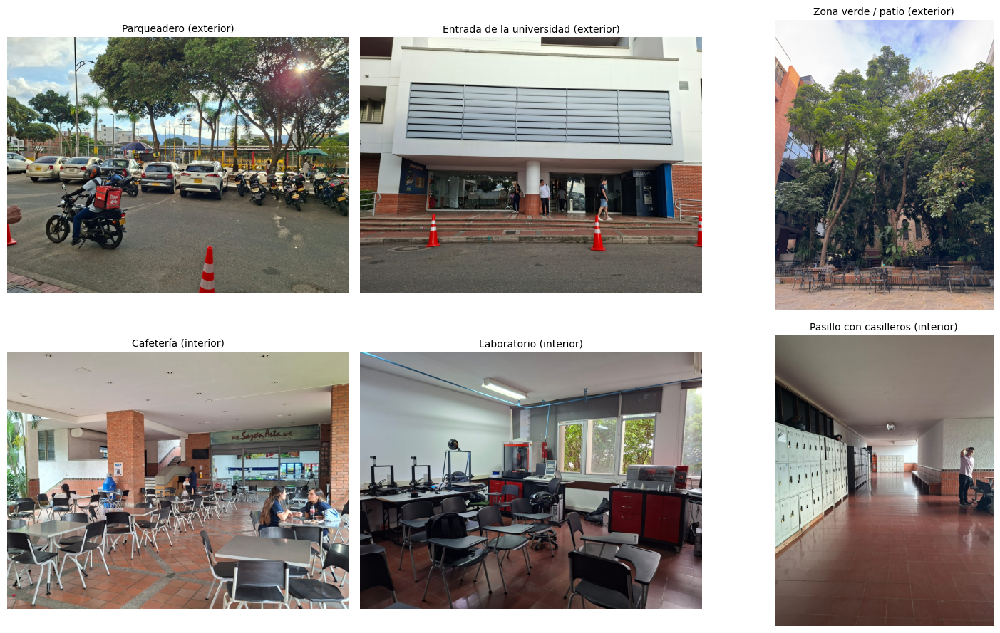

In [7]:
ESCENAS = {
    "01_parqueadero.jpg": "Parqueadero (exterior)",
    "02_entrada_universidad.jpg": "Entrada de la universidad (exterior)",
    "03_zona_verde.jpg": "Zona verde / patio (exterior)",
    "04_cafeteria.jpg": "Cafetería (interior)",
    "05_laboratorio.jpg": "Laboratorio (interior)",
    "06_pasillo_casilleros.jpg": "Pasillo con casilleros (interior)",
}
rutas = [os.path.join(DIR_IMG, n) for n in ESCENAS]
imagenes = {os.path.basename(r): ImageOps.exif_transpose(Image.open(r)).convert("RGB") for r in rutas}

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, (n, im) in zip(axs.ravel(), imagenes.items()):
    ax.imshow(im); ax.set_title(ESCENAS[n], fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## Parte 2. Inferencia panóptica con Mask2Former

In [8]:
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = Mask2FormerForUniversalSegmentation.from_pretrained(MODEL_ID).to(device).eval()

id2label = model.config.id2label
N_THINGS = 80                                   # COCO panoptic: ids 0-79 = thing, 80-132 = stuff
STUFF_IDS = {i for i in id2label if i >= N_THINGS}
print(len(id2label), "clases |", N_THINGS, "thing +", len(STUFF_IDS), "stuff")

ID_EXTRA0 = 1000                                 # ids de clases extra (extensión), siempre tipo thing
def es_thing(label_id):
    return label_id < N_THINGS or label_id >= ID_EXTRA0

preprocessor_config.json:   0%|          | 0.00/538 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/82.2k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  866MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  866MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-coco-panoptic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

133 clases | 80 thing + 53 stuff


In [9]:
@torch.no_grad()
def panoptico(img, umbral=0.5):
    inputs = processor(images=img, return_tensors="pt").to(device)
    out = model(**inputs)
    res = processor.post_process_panoptic_segmentation(
        out, target_sizes=[img.size[::-1]], threshold=umbral,
        label_ids_to_fuse=STUFF_IDS)[0]          # stuff: un solo segmento por clase
    return res["segmentation"].cpu().numpy(), res["segments_info"]

resultados = {n: panoptico(im) for n, im in imagenes.items()}
print("Listo:", len(resultados), "imágenes segmentadas")

Listo: 6 imágenes segmentadas


## Parte 2b (extra). Clases que COCO no tiene: impresoras 3D
Al revisar el laboratorio, Mask2Former **no detecta las impresoras 3D**. No es un tema de umbral: el modelo solo conoce las 133 clases de COCO panoptic y ninguna es "impresora 3D" ni "máquina CNC", así que esas zonas se las come `table`/`cabinet`.

Para mejorarlo agregamos un paso extra, dejando Mask2Former como base:
1. **OWLv2** (detector con texto libre) encuentra cajas para "a 3D printer" y "a CNC milling machine".
2. **SAM** convierte cada caja en una máscara.
3. Las máscaras se pegan como nuevas instancias *thing* (solo sobre píxeles de fondo, sin pisar personas ni sillas ya detectadas).

Si algo falla al cargar, el notebook sigue con el resultado base. Se apaga con `USAR_EXTENSION = False`.

In [10]:
USAR_EXTENSION = True
EXTRA = {"a 3D printer": "3d printer", "a CNC milling machine": "cnc machine"}   # texto del prompt -> nombre de clase
EXTRA_IMGS = ["05_laboratorio.jpg"]            # imágenes donde se aplica
UMBRAL_EXTRA = 0.2                             # bájalo (0.1-0.15) si faltan impresoras, súbelo si hay falsos positivos

for k, nombre in enumerate(EXTRA.values()):
    id2label[ID_EXTRA0 + k] = nombre
resultados_base = dict(resultados)

In [11]:
def detectar_extra(img):
    out = detector(img, candidate_labels=list(EXTRA))
    return [dict(label=d["label"], score=float(d["score"]),
                 box=[d["box"]["xmin"], d["box"]["ymin"], d["box"]["xmax"], d["box"]["ymax"]])
            for d in out if d["score"] >= UMBRAL_EXTRA]

@torch.no_grad()
def mascaras_sam(img, boxes):
    inputs = sam_proc(img, input_boxes=[boxes], return_tensors="pt").to(device)
    out = sam(**inputs, multimask_output=False)
    m = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0]
    return m[:, 0].numpy().astype(bool)           # (n_cajas, H, W)

def fusionar(seg, info, dets, masks):
    seg2, info2 = seg.copy(), [dict(s) for s in info]
    ocupado = np.isin(seg, [s["id"] for s in info if es_thing(s["label_id"])])   # no pisar thing ya detectados
    nuevo = int(seg.max()) + 1
    for d, m in zip(dets, masks):
        m = m & ~ocupado
        if m.sum() < 0.0005 * m.size:
            continue
        seg2[m] = nuevo
        info2.append(dict(id=nuevo, label_id=ID_EXTRA0 + list(EXTRA).index(d["label"]), score=d["score"], was_fused=False))
        nuevo += 1
    return seg2, info2

def extender(img, seg, info):
    from torchvision.ops import batched_nms
    dets = detectar_extra(img)
    if not dets:
        return seg, info, []
    cajas = torch.tensor([d["box"] for d in dets], dtype=torch.float32)
    keep = batched_nms(cajas, torch.tensor([d["score"] for d in dets]),
                       torch.tensor([list(EXTRA).index(d["label"]) for d in dets]), 0.4).tolist()
    dets = [dets[i] for i in keep]
    masks = mascaras_sam(img, [d["box"] for d in dets])
    seg2, info2 = fusionar(seg, info, dets, masks)
    return seg2, info2, dets

if USAR_EXTENSION:
    try:
        from transformers import pipeline, SamModel, SamProcessor
        detector = pipeline("zero-shot-object-detection", model="google/owlv2-base-patch16-ensemble",
                            device=0 if device == "cuda" else -1)
        sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")
        sam = SamModel.from_pretrained("facebook/sam-vit-base").to(device).eval()
        for n in EXTRA_IMGS:
            seg2, info2, dets = extender(imagenes[n], *resultados[n])
            resultados[n] = (seg2, info2)
            print(n, "->", len(dets), "detecciones extra:", [(d["label"], round(d["score"], 2)) for d in dets])
    except Exception as e:
        resultados = dict(resultados_base)
        print("No se pudo aplicar la extensión, se sigue con Mask2Former solo:", repr(e))

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

05_laboratorio.jpg -> 4 detecciones extra: [('a 3D printer', 0.56), ('a 3D printer', 0.54), ('a CNC milling machine', 0.33), ('a 3D printer', 0.22)]


## Parte 3. Visualización (original · mapa segmentado · superposición)

In [12]:
def colorear(seg, info):
    col = np.zeros((*seg.shape, 3), np.uint8)            # negro = píxeles sin etiqueta
    for s in info:
        base = np.random.RandomState(s["label_id"] * 13 + 5).randint(50, 220, 3)
        if es_thing(s["label_id"]):                       # cada instancia con un tono distinto
            base = np.clip(base + np.random.RandomState(s["id"] * 31).randint(-45, 45, 3), 0, 255)
        col[seg == s["id"]] = base
    return col

def pct_sin_etiqueta(seg, info):
    return 100 * (~np.isin(seg, [s["id"] for s in info])).mean()

def punto_interior(mask):
    ys, xs = np.nonzero(mask)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    dt = ndimage.distance_transform_edt(np.pad(mask[y0:y1, x0:x1], 1))   # el borde de la imagen cuenta como fondo
    y, x = np.unravel_index(dt.argmax(), dt.shape)
    return x - 1 + x0, y - 1 + y0

def mostrar(nombre, img, seg, info, guardar=True):
    arr = np.array(img)
    col = colorear(seg, info)
    over = (0.55 * arr + 0.45 * col).astype(np.uint8)
    H, W = seg.shape
    fig, axs = plt.subplots(1, 3, figsize=(20, 8))
    for ax, im, t in zip(axs, (arr, col, over), ("Original", "Segmentación panóptica", "Superposición")):
        ax.imshow(im); ax.set_title(t, fontsize=13); ax.axis("off")
    cont, puestos, leyenda = {}, [], {}
    for s in sorted(info, key=lambda s: -(seg == s["id"]).sum()):
        m = seg == s["id"]
        pct = 100 * m.mean()
        thing = es_thing(s["label_id"])
        nom = id2label[s["label_id"]].replace("-merged", "").replace("-other", "")
        if nom not in leyenda and len(leyenda) < 10:
            y_, x_ = np.argwhere(m)[0]
            leyenda[nom] = col[y_, x_] / 255
        if pct < (0.25 if thing else 2.0):
            continue
        if thing:
            cont[nom] = cont.get(nom, 0) + 1
            nom = f"{nom} {cont[nom]}"
        x, y = punto_interior(m)
        for _ in range(6):                                # separar etiquetas que se pisan
            if any(abs(x - px) < 0.07 * W and abs(y - py) < 0.025 * H for px, py in puestos):
                y += 0.027 * H
            else:
                break
        puestos.append((x, y))
        axs[2].text(x, y, nom, color="black", fontsize=7.5, ha="center", va="center",
                    bbox=dict(facecolor="white", alpha=0.75, pad=1, lw=0))
    from matplotlib.patches import Patch
    handles = [Patch(facecolor=c, label=n) for n, c in leyenda.items()]
    sin = pct_sin_etiqueta(seg, info)
    if sin > 0.1:
        handles.append(Patch(facecolor="black", label=f"sin etiqueta ({sin:.1f}%)"))
    axs[1].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, fontsize=8, frameon=False)
    plt.tight_layout()
    if guardar:
        stem = os.path.splitext(nombre)[0]
        fig.savefig(f"{DIR_OUT}/{stem}_panoptico.png", dpi=110, bbox_inches="tight")
        Image.fromarray(col).save(f"{DIR_OUT}/{stem}_mapa.png")
        Image.fromarray(over).save(f"{DIR_OUT}/{stem}_superposicion.png")
    plt.show()

============================== 01_parqueadero.jpg · Parqueadero (exterior)


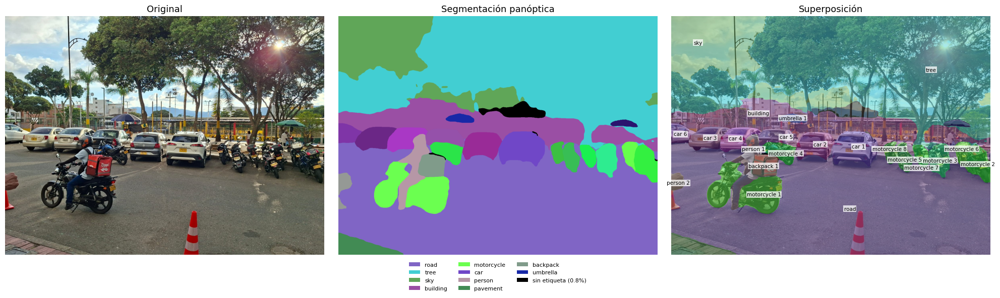

============================== 02_entrada_universidad.jpg · Entrada de la universidad (exterior)


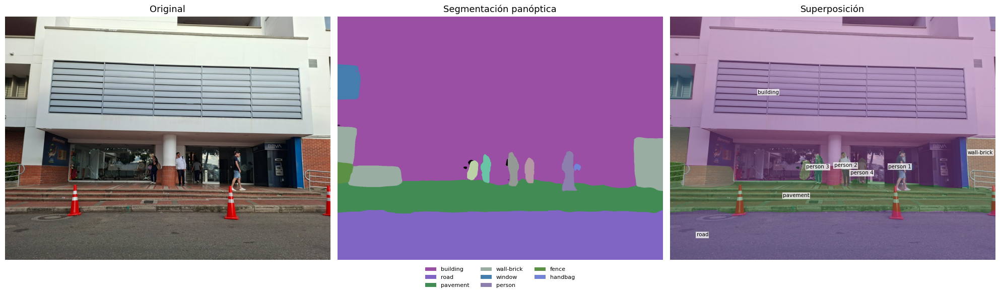

============================== 03_zona_verde.jpg · Zona verde / patio (exterior)


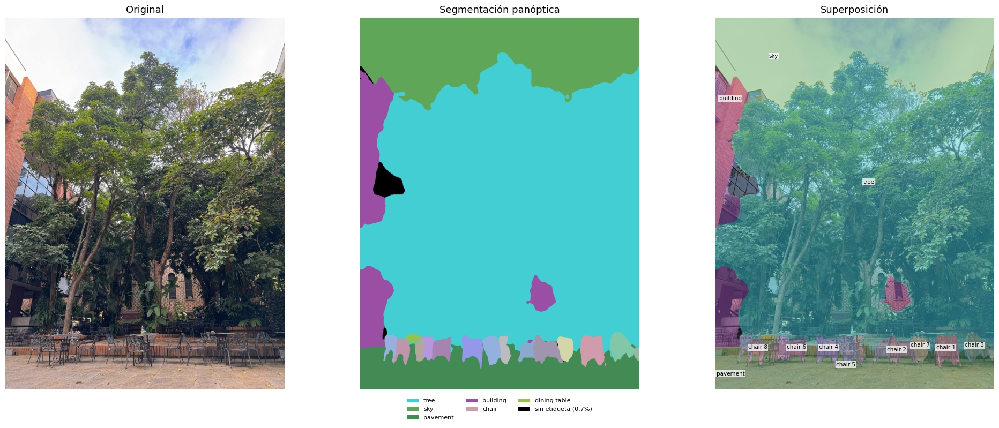

============================== 04_cafeteria.jpg · Cafetería (interior)


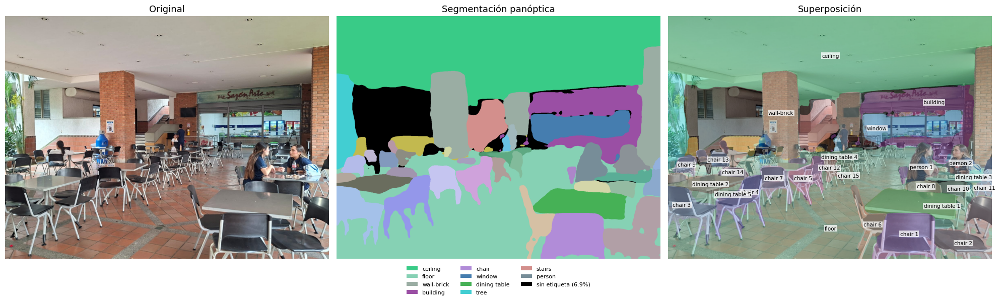

============================== 05_laboratorio.jpg · Laboratorio (interior)


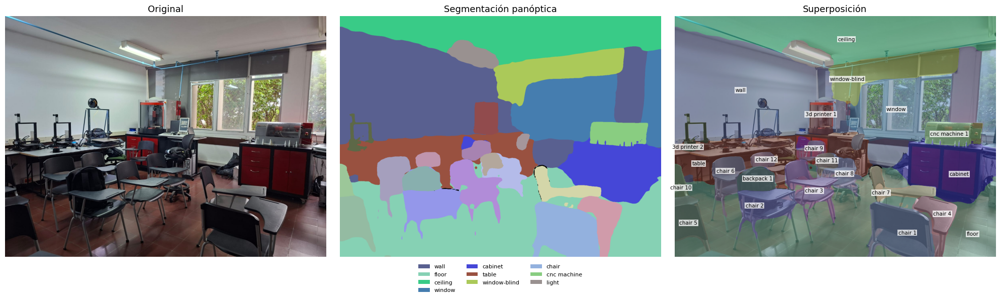

============================== 06_pasillo_casilleros.jpg · Pasillo con casilleros (interior)


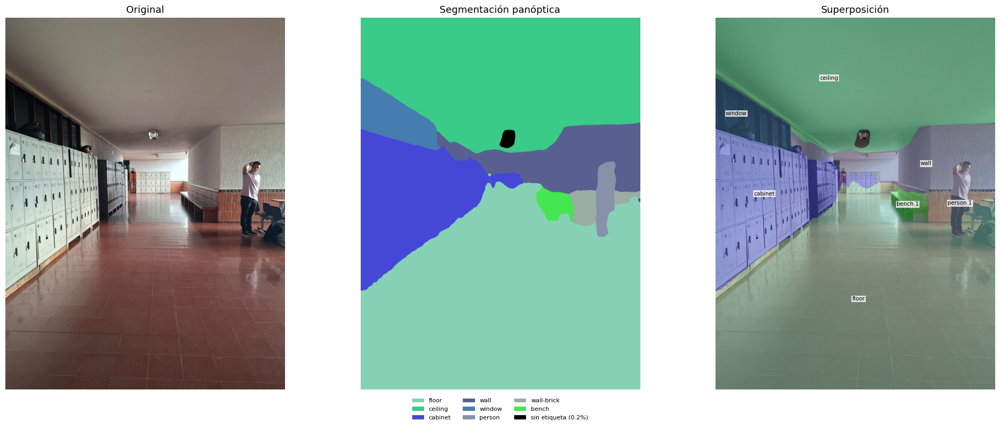

In [13]:
for n, (seg, info) in resultados.items():
    print("=" * 30, n, "·", ESCENAS[n])
    mostrar(n, imagenes[n], seg, info)

## Parte 4. Análisis por imagen
Para cada imagen sacamos: clases *thing*, clases *stuff*, número de instancias por clase y porcentaje de área de cada segmento.

In [14]:
def tabla_segmentos(nombre, seg, info):
    filas = []
    for s in info:
        a = int((seg == s["id"]).sum())
        filas.append(dict(imagen=nombre, seg_id=s["id"], clase=id2label[s["label_id"]],
                          tipo="thing" if es_thing(s["label_id"]) else "stuff",
                          score=round(float(s["score"]), 3), area_px=a, area_pct=round(100 * a / seg.size, 2)))
    return pd.DataFrame(filas).sort_values("area_pct", ascending=False).reset_index(drop=True)

tablas = {n: tabla_segmentos(n, *resultados[n]) for n in resultados}
pd.concat(tablas.values()).to_csv(f"{DIR_OUT}/segmentos_todas.csv", index=False)

for n, df in tablas.items():
    print("=" * 30, n, "·", ESCENAS[n])
    por_clase = (df.groupby(["tipo", "clase"])
                   .agg(instancias=("seg_id", "count"), area_pct=("area_pct", "sum"), score_medio=("score", "mean"))
                   .round(2).sort_values(["tipo", "area_pct"], ascending=[False, False]))
    display(por_clase)
    print("Top 5 segmentos por área:")
    display(df[["clase", "tipo", "area_pct", "score"]].head(5))

============================== 01_parqueadero.jpg · Parqueadero (exterior)


instancias  area_pct  score_medio
tipo  clase                                                   
thing motorcycle                      8      6.48         0.96
      car                             6      5.55         0.95
      person                          2      1.51         0.96
      backpack                        1      0.70         0.94
      umbrella                        2      0.45         0.96
stuff road                            1     34.59         0.99
      tree-merged                     1     32.69         1.00
      sky-other-merged                1      8.57         1.00
      building-other-merged           1      7.66         0.97
      pavement-merged                 1      1.02         0.94

Top 5 segmentos por área:


,clase,tipo,area_pct,score
0,road,stuff,34.59,0.992
1,tree-merged,stuff,32.69,0.999
2,sky-other-merged,stuff,8.57,1.000
3,building-other-merged,stuff,7.66,0.973
4,motorcycle,thing,2.78,0.997


============================== 02_entrada_universidad.jpg · Entrada de la universidad (exterior)


...

,clase,tipo,area_pct,score
0,wall-other-merged,stuff,21.73,0.996
1,floor-other-merged,stuff,17.53,0.986
2,ceiling-merged,stuff,13.24,0.995
3,window-other,stuff,9.05,0.979
4,cabinet-merged,stuff,6.01,0.967


============================== 06_pasillo_casilleros.jpg · Pasillo con casilleros (interior)


instancias  area_pct  score_medio
tipo  clase                                                
thing person                       1      1.10         1.00
      bench                        1      0.82         0.74
stuff floor-other-merged           1     44.74         0.98
      ceiling-merged               1     29.57         1.00
      cabinet-merged               1     12.18         0.98
      wall-other-merged            1      7.45         1.00
      window-other                 1      2.90         0.96
      wall-brick                   1      1.02         0.96

Top 5 segmentos por área:


,clase,tipo,area_pct,score
0,floor-other-merged,stuff,44.74,0.978
1,ceiling-merged,stuff,29.57,0.996
2,cabinet-merged,stuff,12.18,0.983
3,wall-other-merged,stuff,7.45,0.995
4,window-other,stuff,2.90,0.955


### Laboratorio: antes y después de la extensión

ANTES: solo Mask2Former


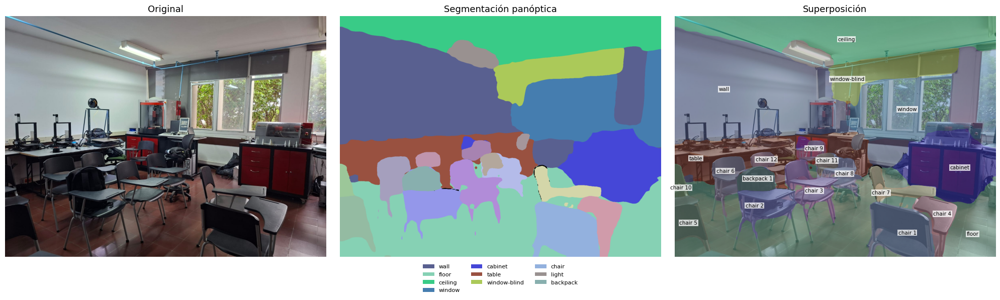

,solo Mask2Former,con extensión
clase,,
3d printer,0,3
backpack,1,1
chair,13,13
cnc machine,0,1


In [15]:
n = "05_laboratorio.jpg"
try:
    if resultados_base[n][1] is not resultados[n][1]:
        print("ANTES: solo Mask2Former")
        mostrar("05_laboratorio_base.jpg", imagenes[n], *resultados_base[n])
        cuenta = lambda df: df[df.tipo == "thing"].groupby("clase").size()
        a, b = tabla_segmentos(n, *resultados_base[n]), tabla_segmentos(n, *resultados[n])
        display(pd.DataFrame({"solo Mask2Former": cuenta(a), "con extensión": cuenta(b)}).fillna(0).astype(int))
    else:
        print("La extensión no se aplicó, no hay comparación.")
except NameError:
    print("La extensión no se aplicó, no hay comparación.")

### Errores o confusiones observadas
Miramos las salidas de la Parte 3 y anotamos lo que se ve mal (objetos sin detectar, clases mal puestas, instancias partidas o juntas…). Se llenan en el diccionario de abajo.

In [16]:
ERRORES = {
    "01_parqueadero.jpg": "Detecta bien los carros (6) y las motos (8), con scores de 0.95 o más. La caja roja de domicilios del conductor la toma como mochila (backpack), y la mano que se asoma en el borde izquierdo cuenta como persona 2. Los conos naranja no existen en COCO y se pierden dentro de road. Las motos estacionadas del fondo salen como manchas pegadas y no siempre coinciden una a una con las reales. Queda 0.8% sin etiqueta (una zona oscura del fondo, detrás de los carros).",
    "02_entrada_universidad.jpg": "Toda la fachada sale como un solo building (62%): las persianas, el ventanal, la vitrina, el cajero BBVA y la columna no se separan porque no hay clases para eso (solo aparece un window pequeño a la izquierda). Los conos naranja quedan dentro de pavement/road y las escaleras se mezclan con pavement. Las 5 personas sí se detectan, pero las que están detrás del vidrio quedan como siluetas incompletas. El handbag (0.62) y el fence (0.59) son segmentos pequeños y de baja confianza.",
    "03_zona_verde.jpg": "El árbol se come casi todo (62.7%): follaje, troncos y hasta parte del edificio de ladrillo del fondo quedan como tree, y solo un pedazo del edificio aparece en el centro. Las sillas de metal calado (14) salen como manchas más gruesas que las sillas reales y muy pegadas entre sí, y casi no se detectan mesas (un solo dining table de 0.09%). Los reflejos del vidrio del edificio de la izquierda quedan sin etiqueta (0.7%). El cielo y el piso salen bien.",
    "04_cafeteria.jpg": "Es la imagen con más errores: 6.9% sin etiqueta (sobre todo la pared del fondo a la izquierda, con ventanas y escalera, y algunos bordes de la barra de comida) y 12 segmentos con score menor a 0.8. La barra con el letrero queda como building y window en vez de mostrador o vitrinas. Con tantas sillas y mesas encimadas (21 sillas y 6 mesas) las instancias se mezclan, las patas se pierden y el conteo no coincide con lo que se ve en la foto (hay más sillas). Las plantas de la izquierda salen como tree.",
    "05_laboratorio.jpg": "Sin la extensión, Mask2Former no detecta ninguna impresora ni máquina: no existen en COCO y quedan absorbidas por table, cabinet y wall. Con la extensión (OWLv2 + SAM) aparecen 3 '3d printer' y 1 'cnc machine', pero solo funcionó a medias: en el mapa se recorta una sola de las impresoras reales (la de la izquierda, y casi solo el marco), las otras dos siguen dentro de table y wall, y la máquina roja del fondo quedó mal etiquetada como impresora 3D (falso positivo). La 'cnc machine' sí cae sobre la máquina del lado derecho. El score medio baja de 0.947 a 0.865 solo porque los scores de OWLv2 (0.33 a 0.44) no son comparables con los de Mask2Former. Los computadores y monitores del fondo no se detectan y quedan dentro de table. Las 13 sillas salen bien aunque encimadas.",
    "06_pasillo_casilleros.jpg": "Es la escena más fácil, pero aun así los casilleros salen como un solo bloque cabinet (no se ve cada casillero) y los del fondo se mezclan con la pared. La silla con paleta y la mochila que están junto a la persona no aparecen como instancias, y la banca tiene score bajo (0.74). La lámpara del techo queda sin etiqueta (0.2%).",
}

### Tabla resumen por imagen

In [17]:
resumen = []
for n, df in tablas.items():
    th, st = df[df.tipo == "thing"], df[df.tipo == "stuff"]
    cuenta = th.groupby("clase").size().sort_values(ascending=False)
    top = df.head(3)
    resumen.append({
        "Imagen": n,
        "Escena": ESCENAS[n],
        "Clases thing (n° instancias)": ", ".join(f"{c} ({k})" for c, k in cuenta.items()) or "-",
        "Clases stuff": ", ".join(st.clase),
        "Total instancias": len(th),
        "Segmento principal (% área)": f"{top.iloc[0].clase} ({top.iloc[0].area_pct}%)",
        "Top 3 segmentos (% área)": ", ".join(f"{r.clase} {r.area_pct}%" for r in top.itertuples()),
        "Score medio": round(df.score.mean(), 3),
        "% sin etiqueta": round(pct_sin_etiqueta(*resultados[n]), 2),
        "Errores / confusiones": ERRORES.get(n, ""),
    })
resumen = pd.DataFrame(resumen)
resumen.to_csv(f"{DIR_OUT}/tabla_resumen.csv", index=False)
try:
    resumen.to_excel(f"{DIR_OUT}/tabla_resumen.xlsx", index=False)
except Exception as e:
    print("No se pudo guardar xlsx:", e)
pd.set_option("display.max_colwidth", None)
display(resumen)

,Imagen,Escena,Clases thing (n° instancias),Clases stuff,Total instancias,Segmento principal (% área),Top 3 segmentos (% área),Score medio,% sin etiqueta,Errores / confusiones
0,01_parqueadero.jpg,Parqueadero (exterior),"motorcycle (8), car (6), person (2), umbrella (2), backpack (1)","road, tree-merged, sky-other-merged, building-other-merged, pavement-merged",19,road (34.59%),"road 34.59%, tree-merged 32.69%, sky-other-merged 8.57%",0.962,0.80,"Detecta bien los carros (6) y las motos (8), con scores de 0.95 o más. La caja roja de domicilios del conductor la toma como mochila (backpack), y la mano que se asoma en el borde izquierdo cuenta como persona 2. Los conos naranja no existen en COCO y se pierden dentro de road. Las motos estacionadas del fondo salen como manchas pegadas y no siempre coinciden una a una con las reales. Queda 0.8% sin etiqueta (una zona oscura del fondo, detrás de los carros)."
1,02_entrada_universidad.jpg,Entrada de la universidad (exterior),"person (5), handbag (1)","building-other-merged, road, pavement-merged, wall-brick, window-other, fence-merged",6,building-other-merged (62.0%),"building-other-merged 62.0%, road 19.84%, pavement-merged 11.28%",0.900,0.04,"Toda la fachada sale como un solo building (62%): las persianas, el ventanal, la vitrina, el cajero BBVA y la columna no se separan porque no hay clases para eso (solo aparece un window pequeño a la izquierda). Los conos naranja quedan dentro de pavement/road y las escaleras se mezclan con pavement. Las 5 personas sí se detectan, pero las que están detrás del vidrio quedan como siluetas incompletas. El handbag (0.62) y el fence (0.59) son segmentos pequeños y de baja confianza."
2,03_zona_verde.jpg,Zona verde / patio (exterior),"chair (14), dining table (1)","tree-merged, sky-other-merged, pavement-merged, building-other-merged",15,tree-merged (62.74%),"tree-merged 62.74%, sky-other-merged 17.63%, pavement-merged 8.88%",0.899,0.72,"El árbol se come casi todo (62.7%): follaje, troncos y hasta parte del edificio de ladrillo del fondo quedan como tree, y solo un pedazo del edificio aparece en el centro. Las sillas de metal calado (14) salen como manchas más gruesas que las sillas reales y muy pegadas entre sí, y casi no se detectan mesas (un solo dining table de 0.09%). Los reflejos del vidrio del edificio de la izquierda quedan sin etiqueta (0.7%). El cielo y el piso salen bien."
3,04_cafeteria.jpg,Cafetería (interior),"chair (21), dining table (6), person (5)","ceiling-merged, floor-other-merged, wall-brick, building-other-merged, window-other, tree-merged, stairs, wall-wood",32,ceiling-merged (28.66%),"ceiling-merged 28.66%, floor-other-merged 20.15%, wall-brick 7.68%",0.862,6.87,"Es la imagen con más errores: 6.9% sin etiqueta (sobre todo la pared del fondo a la izquierda, con ventanas y escalera, y algunos bordes de la barra de comida) y 12 segmentos con score menor a 0.8. La barra con el letrero queda como building y window en vez de mostrador o vitrinas. Con tantas sillas y mesas encimadas (21 sillas y 6 mesas) las instancias se mezclan, las patas se pierden y el conteo no coincide con lo que se ve en la foto (hay más sillas). Las plantas de la izquierda salen como tree."
4,05_laboratorio.jpg,Laboratorio (interior),"chair (13), 3d printer (3), backpack (1), cnc machine (1)","wall-other-merged, floor-other-merged, ceiling-merged, window-other, cabinet-merged, table-merged, window-blind, light",18,wall-other-merged (21.73%),"wall-other-merged 21.73%, floor-other-merged 17.53%, ceiling-merged 13.24%",0.865,0.05,"Sin la extensión, Mask2Former no detecta ninguna impresora ni máquina: no existen en COCO y quedan absorbidas por table, cabinet y wall. Con la extensión (OWLv2 + SAM) aparecen 3 '3d printer' y 1 'cnc machine', pero solo funcionó a medias: en el mapa se recorta una sola de las impresoras reales (la de la izquierda, y casi solo el marco), las otras dos siguen dentro de table y wall, y la máquina roja del fondo quedó mal etiquetada como i

## Parte 5. Conclusiones
Comparamos las escenas con unas métricas rápidas (score medio, segmentos de baja confianza y píxeles sin etiqueta) y con lo que vimos a ojo en las salidas.

In [18]:
comp = []
for n, (seg, info) in resultados.items():
    sc = np.array([s["score"] for s in info])
    comp.append({"Imagen": n, "Escena": ESCENAS[n], "Segmentos": len(info),
                 "Score medio": round(sc.mean(), 3), "Segmentos con score < 0.8": int((sc < 0.8).sum()),
                 "% píxeles sin etiqueta": round(pct_sin_etiqueta(seg, info), 2)})
comp = pd.DataFrame(comp)
comp.to_csv(f"{DIR_OUT}/comparacion_escenas.csv", index=False)
display(comp)

,Imagen,Escena,Segmentos,Score medio,Segmentos con score < 0.8,% píxeles sin etiqueta
0,01_parqueadero.jpg,Parqueadero (exterior),24,0.962,1,0.80
1,02_entrada_universidad.jpg,Entrada de la universidad (exterior),12,0.900,2,0.04
2,03_zona_verde.jpg,Zona verde / patio (exterior),19,0.899,3,0.72
3,04_cafeteria.jpg,Cafetería (interior),40,0.862,12,6.87
4,05_laboratorio.jpg,Laboratorio (interior),26,0.865,4,0.05
5,06_pasillo_casilleros.jpg,Pasillo con casilleros (interior),8,0.951,1,0.21


Comparamos el **parqueadero**, la **cafetería** y el **laboratorio** (con el pasillo como apoyo).

| Imagen | Score medio | Segmentos con score < 0.8 | % sin etiqueta | Instancias |
|---|---|---|---|---|
| Parqueadero | 0.96 | 1 | 0.8 | 19 |
| Pasillo | 0.95 | 1 | 0.2 | 2 |
| Laboratorio | 0.87 (0.95 solo con Mask2Former) | 4 | 0.05 | 18 |
| Cafetería | 0.86 | 12 | 6.9 | 32 |

**En qué escenas funcionó mejor:** en el parqueadero y en el pasillo. En el parqueadero los objetos (carros, motos, personas) son grandes y están bien separados, y en el pasillo la escena es simple y dominada por regiones amplias (piso, techo, casilleros). En todas las imágenes las regiones stuff grandes (cielo, calle, piso, techo, árboles) salieron con score de 0.97 o más, y las personas también (0.94 a 1.0).

**En cuáles falló:** sobre todo en la cafetería: tiene el score medio más bajo, 12 segmentos poco confiables y casi 7% de la imagen sin etiqueta, porque hay muchas sillas y mesas encimadas y zonas del fondo (pared con ventanas, escalera y barra de comida) que el modelo no logra clasificar. En el laboratorio falló con las impresoras 3D y las máquinas, y en la entrada la fachada quedó como una sola región enorme de building.

**Qué objetos o regiones fueron más difíciles:**
- **Objetos que no están en COCO:** impresoras 3D, máquinas, conos, cajero, puertas. El modelo los mete dentro del stuff que los rodea (table, cabinet, road, building). Para el laboratorio probamos agregar OWLv2 + SAM: detectó la máquina del lado derecho y una de las tres impresoras, pero marcó como impresora la máquina roja y dejó sin detectar las otras dos. Ayuda, pero no resuelve el problema.
- **Muchos objetos pequeños y encimados:** sillas y mesas de la cafetería, sillas de metal de la zona verde y motos del fondo del parqueadero. Las instancias se pegan y el conteo no es exacto.
- **Vidrios y reflejos:** el ventanal de la entrada, las vitrinas de la cafetería y las ventanas del edificio de la zona verde quedaron sin etiqueta o mal clasificadas.
- **Objetos con poca área:** monitores del laboratorio, la mochila junto a la persona del pasillo, el handbag de la entrada. Salen con scores bajos o no salen.

**Conclusión general:** Mask2Former funciona muy bien para regiones grandes y objetos comunes y visibles, pero está limitado por las 133 clases de COCO y por las escenas con mucha oclusión. Para mejorar habría que usar un modelo con más clases o hacer fine-tuning con un dataset propio del campus.

## Parte 6. Aplicación web interactiva
El enunciado pide **desplegar los resultados en una aplicación web** donde se puedan visualizar las predicciones sobre imágenes nuevas. Hicimos una app con **Gradio**: se sube una foto (o se escoge un ejemplo del campus), el modelo la segmenta y la app muestra:
- la imagen original,
- el mapa segmentado,
- una superposición interactiva (al pasar el mouse sobre un segmento sale su clase y su % de área),
- el resumen de objetos *thing* y una tabla con clase, instancias, % de área y score.

La app queda en `app.py` (también va en la entrega, junto con `requirements.txt` y un `README.md` con los pasos para publicarla en Hugging Face Spaces). Abajo la escribimos y la lanzamos desde el notebook reutilizando el modelo que ya cargamos.

In [19]:
!pip -q install -U gradio

In [20]:
%%writefile app.py
"""
Segmentación panóptica del campus - aplicación web interactiva (Gradio)
Electiva IV - Deep Computer Vision, USTA

Modelo: Mask2Former preentrenado en COCO panoptic (Hugging Face).
Opcional: OWLv2 + SAM para clases que COCO no tiene (impresoras 3D, máquinas CNC).

Uso local / Colab / Hugging Face Spaces:  python app.py
"""
import os
import glob

import numpy as np
import pandas as pd
import gradio as gr
from PIL import Image, ImageOps

MODEL_ID = os.environ.get("MODEL_ID", "facebook/mask2former-swin-large-coco-panoptic")
# En CPU (Spaces gratis) conviene: MODEL_ID=facebook/mask2former-swin-tiny-coco-panoptic
N_THINGS = 80                      # COCO panoptic: ids 0-79 thing, 80-132 stuff
ID_EXTRA0 = 1000                   # ids de clases extra (extensión), siempre thing
EXTRA = {"a 3D printer": "3d printer", "a CNC milling machine": "cnc machine"}
UMBRAL_EXTRA = 0.2
MAX_LADO = 1280                    # se reduce la imagen si es más grande (más rápido)

_M = {}                            # caché de modelos


# ----------------------------------------------------------------- modelos
def inyectar(model, processor, detector=None, sam_proc=None, sam=None):
    """Reutiliza modelos ya cargados (por ejemplo, los del notebook) para no cargarlos dos veces."""
    _M["model"], _M["proc"] = model, processor
    _M["device"] = str(next(model.parameters()).device).split(":")[0]
    _M["id2label"] = _id2label(model)
    if detector is not None and sam_proc is not None and sam is not None:
        _M.update(detector=detector, sam_proc=sam_proc, sam=sam)


def _id2label(model):
    d = {int(k): v for k, v in model.config.id2label.items() if int(k) < ID_EXTRA0}
    for k, nombre in enumerate(EXTRA.values()):
        d[ID_EXTRA0 + k] = nombre
    return d


def _cargar():
    if "model" not in _M:
        import torch
        from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation
        device = "cuda" if torch.cuda.is_available() else "cpu"
        _M["proc"] = AutoImageProcessor.from_pretrained(MODEL_ID)
        _M["model"] = Mask2FormerForUniversalSegmentation.from_pretrained(MODEL_ID).to(device).eval()
        _M["device"] = device
        _M["id2label"] = _id2label(_M["model"])
    return _M


def _cargar_extension():
    m = _cargar()
    if "detector" not in m:
        from transformers import pipeline, SamModel, SamProcessor
        m["detector"] = pipeline("zero-shot-object-detection", model="google/owlv2-base-patch16-ensemble",
                                 device=0 if m["device"] == "cuda" else -1)
        m["sam_proc"] = SamProcessor.from_pretrained("facebook/sam-vit-base")
        m["sam"] = SamModel.from_pretrained("facebook/sam-vit-base").to(m["device"]).eval()
    return m


# ----------------------------------------------------------------- inferencia
def es_thing(label_id):
    return label_id < N_THINGS or label_id >= ID_EXTRA0


def panoptico(img, umbral=0.5):
    import torch
    m = _cargar()
    inputs = m["proc"](images=img, return_tensors="pt").to(m["device"])
    with torch.no_grad():
        out = m["model"](**inputs)
    stuff = {i for i in m["id2label"] if N_THINGS <= i < ID_EXTRA0}
    res = m["proc"].post_process_panoptic_segmentation(
        out, target_sizes=[img.size[::-1]], threshold=umbral, label_ids_to_fuse=stuff)[0]
    if res["segmentation"] is None:                       # nada superó el umbral
        return np.zeros(img.size[::-1], dtype=np.int32), []
    return res["segmentation"].cpu().numpy(), res["segments_info"]


def extender(img, seg, info):
    """OWLv2 (cajas con texto) + SAM (máscaras): agrega impresoras 3D y máquinas CNC como instancias thing."""
    import torch
    from torchvision.ops import batched_nms
    m = _cargar_extension()
    out = m["detector"](img, candidate_labels=list(EXTRA))
    dets = [dict(label=d["label"], score=float(d["score"]),
                 box=[d["box"]["xmin"], d["box"]["ymin"], d["box"]["xmax"], d["box"]["ymax"]])
            for d in out if d["score"] >= UMBRAL_EXTRA]
    if not dets:
        return seg, info
    cajas = torch.tensor([d["box"] for d in dets], dtype=torch.float32)
    keep = batched_nms(cajas, torch.tensor([d["score"] for d in dets]),
                       torch.tensor([list(EXTRA).index(d["label"]) for d in dets]), 0.4).tolist()
    dets = [dets[i] for i in keep]
    with torch.no_grad():
        inputs = m["sam_proc"](img, input_boxes=[[d["box"] for d in dets]], return_tensors="pt").to(m["device"])
        pred = m["sam"](**inputs, multimask_output=False)
        masks = m["sam_proc"].image_processor.post_process_masks(
            pred.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0]
    return fusionar(seg, info, dets, masks[:, 0].numpy().astype(bool))


def fusionar(seg, info, dets, masks):
    seg2, info2 = seg.copy(), [dict(s) for s in info]
    ocupado = np.isin(seg, [s["id"] for s in info if es_thing(s["label_id"])])    # no pisar thing ya detectados
    nuevo = int(seg.max()) + 1
    for d, mask in zip(dets, masks):
        mask = mask & ~ocupado
        if mask.sum() < 0.0005 * mask.size:
            continue
        seg2[mask] = nuevo
        info2.append(dict(id=nuevo, label_id=ID_EXTRA0 + list(EXTRA).index(d["label"]), score=d["score"], was_fused=False))
        nuevo += 1
    return seg2, info2


# ----------------------------------------------------------------- visualización
def _nombre(id2label, label_id):
    return id2label[label_id].replace("-merged", "").replace("-other", "")


def colorear(seg, info):
    col = np.zeros((*seg.shape, 3), np.uint8)             # negro = sin etiqueta
    for s in info:
        base = np.random.RandomState(s["label_id"] * 13 + 5).randint(50, 220, 3)
        if es_thing(s["label_id"]):                       # cada instancia con un tono distinto
            base = np.clip(base + np.random.RandomState(s["id"] * 31).randint(-45, 45, 3), 0, 255)
        col[seg == s["id"]] = base
    return col


def analizar(img, seg, info, id2label):
    """Devuelve (capas para AnnotatedImage, tabla por clase, texto resumen)."""
    capas, filas, cont = [], [], {}
    for s in sorted(info, key=lambda s: -(seg == s["id"]).sum()):
        mask = seg == s["id"]
        pct = 100 * mask.mean()
        thing = es_thing(s["label_id"])
        nom = _nombre(id2label, s["label_id"])
        filas.append(dict(clase=nom, tipo="thing" if thing else "stuff", score=float(s["score"]), area_pct=pct))
        if pct >= 0.2:
            if thing:
                cont[nom] = cont.get(nom, 0) + 1
                etiqueta = f"{nom} {cont[nom]} ({pct:.1f}%)"
            else:
                etiqueta = f"{nom} ({pct:.1f}%)"
            capas.append((mask.astype(np.float32), etiqueta))
    sin_etiqueta = 100 * (~np.isin(seg, [s["id"] for s in info])).mean()

    if filas:
        df = pd.DataFrame(filas)
        tabla = (df.groupby(["tipo", "clase"])
                   .agg(instancias=("clase", "count"), area_pct=("area_pct", "sum"), score_medio=("score", "mean"))
                   .round(2).reset_index().sort_values(["tipo", "area_pct"], ascending=[False, False]))
        tabla.columns = ["Tipo", "Clase", "Instancias", "Área (%)", "Score medio"]
    else:
        df = pd.DataFrame(columns=["tipo", "clase"])
        tabla = pd.DataFrame(columns=["Tipo", "Clase", "Instancias", "Área (%)", "Score medio"])

    things = df[df.tipo == "thing"].groupby("clase").size().sort_values(ascending=False)
    n_stuff = int((df.tipo == "stuff").sum())
    texto = (f"**{int(things.sum())} instancias** de {len(things)} clase(s) *thing* · "
             f"{n_stuff} regiones *stuff* · {sin_etiqueta:.1f}% de píxeles sin etiqueta\n\n"
             f"**Objetos (thing):** " + (", ".join(f"{c} ×{n}" for c, n in things.items()) or "ninguno"))
    return capas, tabla, texto


def procesar(img, umbral, usar_ext):
    if img is None:
        raise gr.Error("Primero sube una imagen o escoge uno de los ejemplos.")
    img = ImageOps.exif_transpose(img).convert("RGB")
    img.thumbnail((MAX_LADO, MAX_LADO))
    id2label = _cargar()["id2label"]
    seg, info = panoptico(img, umbral)
    if usar_ext:
        try:
            seg, info = extender(img, seg, info)
        except Exception as e:                            # la app sigue con Mask2Former solo
            gr.Warning(f"No se pudo aplicar la extensión (impresoras/máquinas): {e}")
    capas, tabla, texto = analizar(img, seg, info, id2label)
    return (np.array(img), capas), colorear(seg, info), texto, tabla


# ----------------------------------------------------------------- interfaz
def crear_demo():
    ejemplos = sorted(glob.glob(os.path.join(os.path.dirname(os.path.abspath(__file__)), "imagenes", "*.jpg")))
    with gr.Blocks(title="Segmentación panóptica del campus") as demo:
        gr.Markdown("# Segmentación panóptica del entorno universitario\n"
                    "Sube una foto del campus y **Mask2Former** (COCO panoptic) separa las regiones de fondo (*stuff*) "
                    "y cada objeto individual (*thing*). Pasa el mouse sobre la superposición para ver cada segmento.")
        with gr.Row():
            with gr.Column(scale=1):
                entrada = gr.Image(type="pil", label="Imagen original", sources=["upload", "clipboard"])
                umbral = gr.Slider(0.1, 0.95, value=0.5, step=0.05, label="Umbral de confianza")
                ext = gr.Checkbox(False, label="Detectar también impresoras 3D / máquinas CNC (OWLv2 + SAM, más lento)")
                boton = gr.Button("Segmentar", variant="primary")
            with gr.Column(scale=2):
                anotada = gr.AnnotatedImage(label="Superposición interactiva (pasa el mouse por los segmentos)")
        with gr.Row():
            mapa = gr.Image(label="Mapa segmentado", interactive=False)
            with gr.Column():
                resumen = gr.Markdown()
                tabla = gr.Dataframe(label="Clases detectadas", interactive=False)
        if ejemplos:
            gr.Examples(examples=ejemplos, inputs=entrada, label="Ejemplos del campus")
        boton.click(procesar, [entrada, umbral, ext], [anotada, mapa, resumen, tabla])
    return demo


demo = crear_demo()

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [21]:
import app
app.inyectar(model, processor, globals().get("detector"), globals().get("sam_proc"), globals().get("sam"))
app.demo.launch(share=True)      # abre el link público (gradio.live); el link es temporal

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6868958f180cdf6ec1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Para probarla: abran el link, suban una foto **nueva** del campus (que no sea de las 6 del taller) y den clic en **Segmentar**. Con el check de impresoras/máquinas se usa también OWLv2 + SAM, como en la Parte 2b.

In [22]:
!zip -r salidas.zip salidas
from google.colab import files
files.download("salidas.zip")

  adding: salidas/ (stored 0%)
  adding: salidas/01_parqueadero_mapa.png (deflated 13%)
  adding: salidas/06_pasillo_casilleros_superposicion.png (deflated 0%)
  adding: salidas/02_entrada_universidad_panoptico.png (deflated 1%)
  adding: salidas/04_cafeteria_superposicion.png (deflated 0%)
  adding: salidas/04_cafeteria_panoptico.png (deflated 0%)
  adding: salidas/02_entrada_universidad_superposicion.png (deflated 0%)
  adding: salidas/06_pasillo_casilleros_panoptico.png (deflated 1%)
  adding: salidas/02_entrada_universidad_mapa.png (deflated 50%)
  adding: salidas/05_laboratorio_base_superposicion.png (deflated 0%)
  adding: salidas/03_zona_verde_superposicion.png (deflated 1%)
  adding: salidas/05_laboratorio_base_mapa.png (deflated 11%)
  adding: salidas/04_cafeteria_mapa.png (deflated 10%)
  adding: salidas/06_pasillo_casilleros_mapa.png (deflated 34%)
  adding: salidas/tabla_resumen.csv (deflated 58%)
  adding: salidas/comparacion_escenas.csv (deflated 41%)
  adding: salidas/05

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>